In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = pd.read_csv('exoplanet_data.csv', comment='#')

In [3]:
df.shape

(599, 92)

In [4]:
df.columns.tolist()

['pl_name',
 'hostname',
 'default_flag',
 'sy_snum',
 'sy_pnum',
 'discoverymethod',
 'disc_year',
 'disc_facility',
 'soltype',
 'pl_controv_flag',
 'pl_refname',
 'pl_orbper',
 'pl_orbpererr1',
 'pl_orbpererr2',
 'pl_orbperlim',
 'pl_orbsmax',
 'pl_orbsmaxerr1',
 'pl_orbsmaxerr2',
 'pl_orbsmaxlim',
 'pl_rade',
 'pl_radeerr1',
 'pl_radeerr2',
 'pl_radelim',
 'pl_radj',
 'pl_radjerr1',
 'pl_radjerr2',
 'pl_radjlim',
 'pl_bmasse',
 'pl_bmasseerr1',
 'pl_bmasseerr2',
 'pl_bmasselim',
 'pl_bmassj',
 'pl_bmassjerr1',
 'pl_bmassjerr2',
 'pl_bmassjlim',
 'pl_bmassprov',
 'pl_orbeccen',
 'pl_orbeccenerr1',
 'pl_orbeccenerr2',
 'pl_orbeccenlim',
 'pl_insol',
 'pl_insolerr1',
 'pl_insolerr2',
 'pl_insollim',
 'pl_eqt',
 'pl_eqterr1',
 'pl_eqterr2',
 'pl_eqtlim',
 'ttv_flag',
 'st_refname',
 'st_spectype',
 'st_teff',
 'st_tefferr1',
 'st_tefferr2',
 'st_tefflim',
 'st_rad',
 'st_raderr1',
 'st_raderr2',
 'st_radlim',
 'st_mass',
 'st_masserr1',
 'st_masserr2',
 'st_masslim',
 'st_met',
 'st_me

In [5]:
# Planet Name = pl_name
# Host Name	= hostname
# Discovery Method = discoverymethod
# Spectral Type	= st_spectype
# Equilibrium Temperature [K] = pl_eqt
# Planet Mass or Mass*sin(i) [Jupiter Mass] = pl_bmassj

In [6]:
cols = ['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt', 'pl_bmassj']
df1 = df[cols]

In [7]:
df1 = df1.dropna()

In [8]:
df1.shape

(77, 6)

In [9]:
df1.head()

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
3,DMPP-1 b,DMPP-1,Radial Velocity,F8 V,877.0,0.076362
4,DMPP-1 c,DMPP-1,Radial Velocity,F8 V,1239.0,0.030205
6,DMPP-1 d,DMPP-1,Radial Velocity,F8 V,1632.0,0.010540
8,DMPP-1 e,DMPP-1,Radial Velocity,F8 V,1314.0,0.012994
9,DMPP-2 b,DMPP-2,Radial Velocity,F5 V,1000.0,0.437000


In [10]:
df1.tail()

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
575,WASP-185 b,WASP-185,Transit,G0 V,1160.0,0.980
580,WASP-190 b,WASP-190,Transit,F6 IV-V,1500.0,1.000
584,WASP-192 b,WASP-192,Transit,G0 V,1620.0,2.300
585,XO-7 b,XO-7,Transit,G0 V,1743.0,0.709
597,eps Ind A b,eps Ind A,Radial Velocity,K5 V,275.0,6.310


In [11]:
df1.columns.tolist()

['pl_name',
 'hostname',
 'discoverymethod',
 'st_spectype',
 'pl_eqt',
 'pl_bmassj']

In [12]:
df1['discoverymethod'].value_counts()

discoverymethod
Transit            62
Radial Velocity    13
Imaging             2
Name: count, dtype: int64

In [13]:
# Transit = spectroscopy from in front of star
# Radial Velocity = Star wobbling
# Imaging = photo of the planet

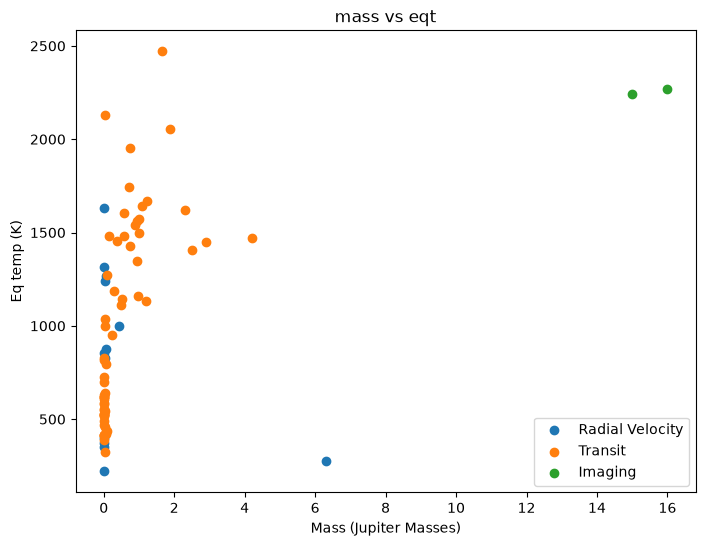

In [14]:
plt.figure(figsize=(8, 6))

for method in df1['discoverymethod'].unique():
    subset = df1[df1['discoverymethod'] == method]
    plt.scatter(subset['pl_bmassj'], subset['pl_eqt'], label=method)

plt.title('mass vs eqt')
plt.xlabel('Mass (Jupiter Masses)')
plt.ylabel('Eq temp (K)')
plt.legend()
plt.show()

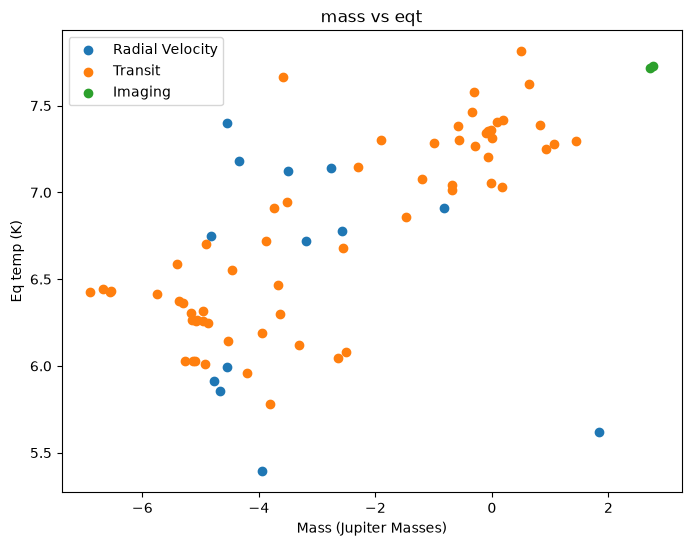

In [15]:
plt.figure(figsize=(8, 6))

for method in df1['discoverymethod'].unique():
    subset = df1[df1['discoverymethod'] == method]
    plt.scatter(np.log(subset['pl_bmassj']), np.log(subset['pl_eqt']), label=method)

plt.title('mass vs eqt')
plt.xlabel('Mass (Jupiter Masses)')
plt.ylabel('Eq temp (K)')
plt.legend()
plt.show()

In [16]:
# more likely to be small

In [17]:
big = df1[df1['pl_bmassj'] > 5]
i = df1['pl_eqt'].idxmin()

In [18]:
print(df1.loc[i])

pl_name                   GJ 357 d
hostname                    GJ 357
discoverymethod    Radial Velocity
st_spectype                 M2.5 V
pl_eqt                       219.6
pl_bmassj                 0.019193
Name: 76, dtype: object


In [19]:
# not sun like

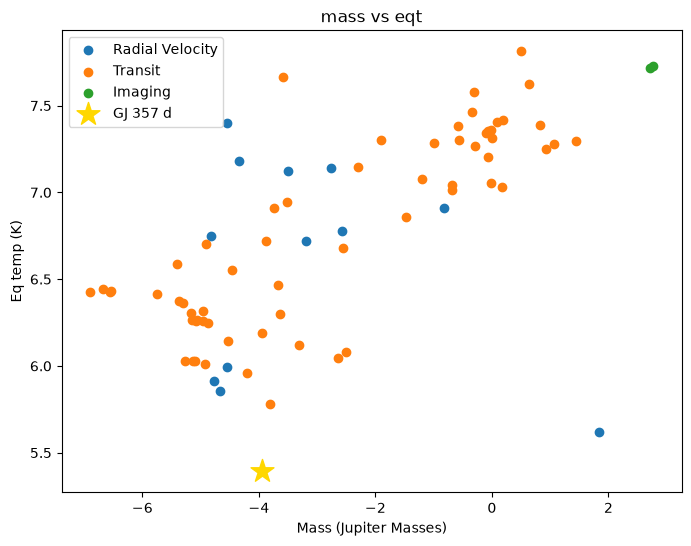

In [22]:
plt.figure(figsize=(8, 6))

for method in df1['discoverymethod'].unique():
    subset = df1[df1['discoverymethod'] == method]
    plt.scatter(np.log(subset['pl_bmassj']), np.log(subset['pl_eqt']), label=method)

plt.scatter(np.log(df1.loc[i, 'pl_bmassj']), np.log(df1.loc[i, 'pl_eqt']),
            color='gold', marker='*', s=300, label=df1.loc[i, 'pl_name'])

plt.title('mass vs eqt')
plt.xlabel('Mass (Jupiter Masses)')
plt.ylabel('Eq temp (K)')
plt.legend()
plt.show()